# Conditional VAE: class-conditional samples and latent structure

Compares the unconditional VAE (prior N(0, I)) with the conditional VAE (prior p(z|y) = N(m(y), I),
with learned class means `classmeans`). Both are loaded from `outputs/` (first seed of each experiment).

1. **Class-conditional samples** from the cVAE, one row per digit, next to unconditional prior samples.
2. **Latent comparison**: encoder means of the validation images coloured by digit, projected to 2D with PCA
   when d > 2, with the cVAE's class means marked.
3. **Separation numbers**: how strongly the latent codes cluster by class in each model.

Validation set only. Figures go to `figures/cvae.pdf`.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import torch
import yaml
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

# repository root: the first folder upwards that contains src/
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.append(str(ROOT))

from src.data import get_loaders
from src.models import build_model

FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)
torch.set_grad_enabled(False)          # analysis only

## Models

Adjust the folder names to your configs. Both models should have the same latent dimension and β,
so that the only difference is the prior.

In [2]:
experiments = {
    "VAE": ROOT / "outputs" / "VAE_d2",
    "cVAE": ROOT / "outputs" / "cVAE_d2",
}

for label, p in experiments.items():
    print(f"{label:5s} {p.name:16s} exists: {p.exists()!s:5s}  seeds: {len(list(p.glob('seed_*')))}")

VAE   VAE_d2           exists: True   seeds: 3
cVAE  cVAE_d2          exists: False  seeds: 0


## Helpers

In [3]:
def seed_dirs(exp_dir):
    dirs = sorted(Path(exp_dir).glob("seed_*"))
    if not dirs:
        raise FileNotFoundError(f"no seed_* folders in {Path(exp_dir).resolve()}")
    return dirs


def load_model(run_dir):
    cfg = yaml.safe_load(open(run_dir / "config.yaml"))
    model = build_model(cfg["model"])
    model.load_state_dict(torch.load(run_dir / "model.pt", map_location="cpu"))
    return model.eval(), cfg


def encode(model, x):
    """Deterministic latent code: model.encode if defined, else the encoder mean."""
    if hasattr(model, "encode"):
        return model.encode(x)
    return model.encoder(x)[:, 0]


def latent_codes(model, loader):
    zs, ys = [], []
    for images, labels in loader:
        zs.append(encode(model, images))
        ys.append(labels)
    return torch.cat(zs).numpy(), torch.cat(ys).numpy()


def class_means(model):
    """The learned prior means m(0), ..., m(9) as a (10, d) array."""
    return model.classmeans.weight.numpy()


def pca(z, k=2):
    """Project z onto its first k principal components. Returns (projection, project_fn, explained)."""
    center = z.mean(axis=0)
    _, s, vt = np.linalg.svd(z - center, full_matrices=False)
    project = lambda a: (a - center) @ vt[:k].T
    explained = (s[:k] ** 2) / (s ** 2).sum()
    return project(z), project, explained


def to_image(t):
    return t.squeeze(1).cpu().numpy()


def image_grid(images, n_rows, n_cols):
    h, w = images.shape[1:]
    return images.reshape(n_rows, n_cols, h, w).transpose(0, 2, 1, 3).reshape(n_rows * h, n_cols * w)

In [5]:
models = {label: load_model(seed_dirs(p)[0])[0] for label, p in experiments.items()}
assert hasattr(models["cVAE"], "classmeans"), "the conditional model needs a `classmeans` embedding"
d = models["cVAE"].dim_latent
print("latent dimension:", d)

first_run = seed_dirs(experiments["VAE"])[0]
data_cfg = yaml.safe_load(open(first_run / "config.yaml"))["data"]
data_cfg.pop("train_subset", None)
_, val_loader, _ = get_loaders(**data_cfg)        # the test loader is not used here

pdf = PdfPages(FIG_DIR / "cvae.pdf")

latent dimension: 2


## 1. Class-conditional samples

Left: cVAE, row c shows z ~ N(m(c), I) decoded; the first column (framed) decodes the class mean m(c) itself.
Right: the unconditional VAE's samples from N(0, I), which cannot be steered to a class.
The same noise ε is used in every row of the cVAE grid, so differences between rows come only from the class mean.

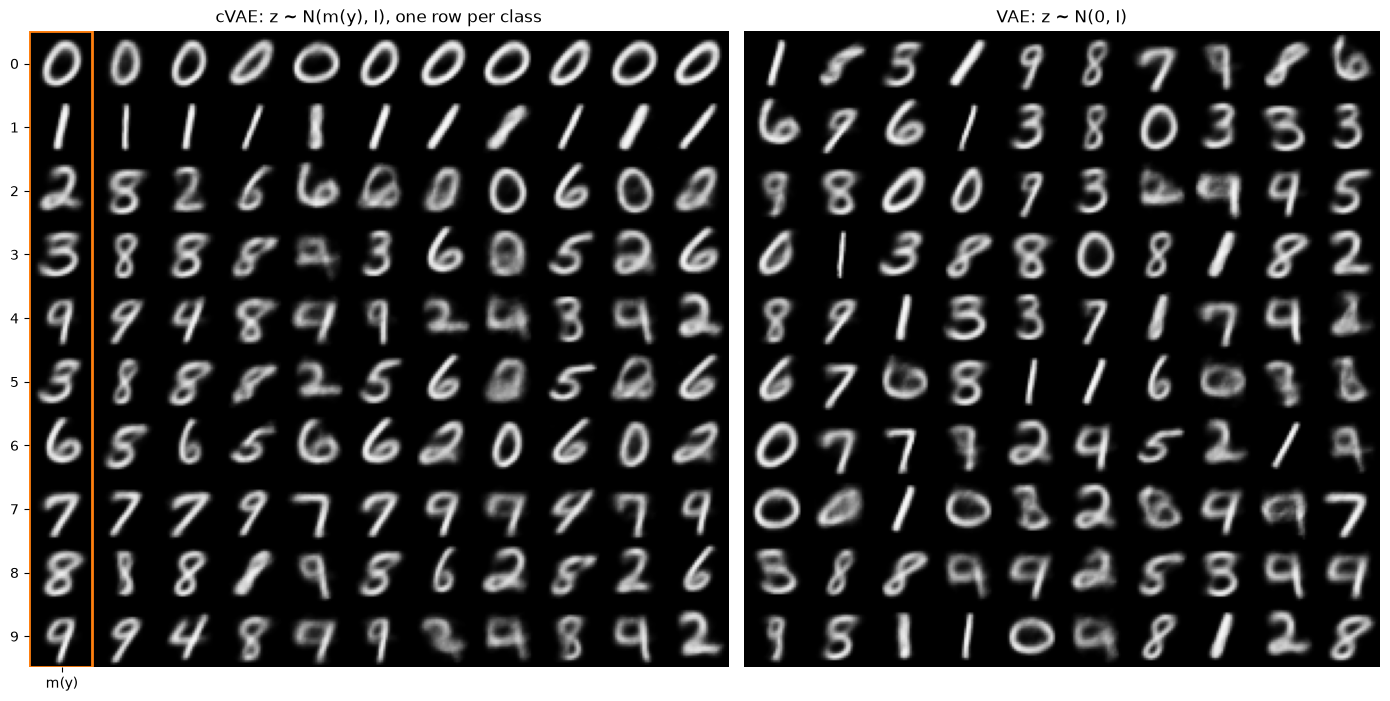

In [10]:
n_cols = 10
gen = torch.Generator().manual_seed(0)
eps = torch.randn(n_cols, d, generator=gen)                       # shared across classes

cvae = models["cVAE"]
m = cvae.classmeans.weight                                        # (10, d)
rows = []
for c in range(10):
    z = torch.cat([m[c:c + 1], m[c] + eps])                       # class mean, then samples
    rows.append(to_image(cvae.decoder(z)))
cond_grid = image_grid(np.concatenate(rows), 10, n_cols + 1)

uncond_z = torch.randn(10 * n_cols, d, generator=torch.Generator().manual_seed(1))
uncond_grid = image_grid(to_image(models["VAE"].decoder(uncond_z)), 10, n_cols)

fig, axes = plt.subplots(1, 2, figsize=(14, 6.8), gridspec_kw={"width_ratios": [n_cols + 1, n_cols]})
axes[0].imshow(cond_grid, cmap="gray", vmin=0, vmax=1)
axes[0].add_patch(plt.Rectangle((-0.5, -0.5), 28, 280, fill=False, edgecolor="tab:orange", linewidth=2))
axes[0].set_yticks(np.arange(10) * 28 + 14, [str(c) for c in range(10)])
axes[0].set_xticks([14], ["m(y)"])
axes[0].set_title("cVAE: z ~ N(m(y), I), one row per class")
axes[1].imshow(uncond_grid, cmap="gray", vmin=0, vmax=1)
axes[1].set_xticks([])
axes[1].set_yticks([])
axes[1].set_title("VAE: z ~ N(0, I)")
for ax in axes:
    for spine in ax.spines.values():
        spine.set_visible(False)

plt.tight_layout()
pdf.savefig(fig, bbox_inches="tight")
plt.show()

fig.savefig(FIG_DIR / "conditional_samples.pdf", bbox_inches="tight")


## 2. Latent structure

Encoder means of all validation images, coloured by digit. For d = 2 the codes are shown directly;
for d > 2 each model's codes are projected onto their own first two principal components
(the explained variance is given in the title), so axes are not comparable between panels.
On the cVAE panel, the projected class means are marked with their digit.

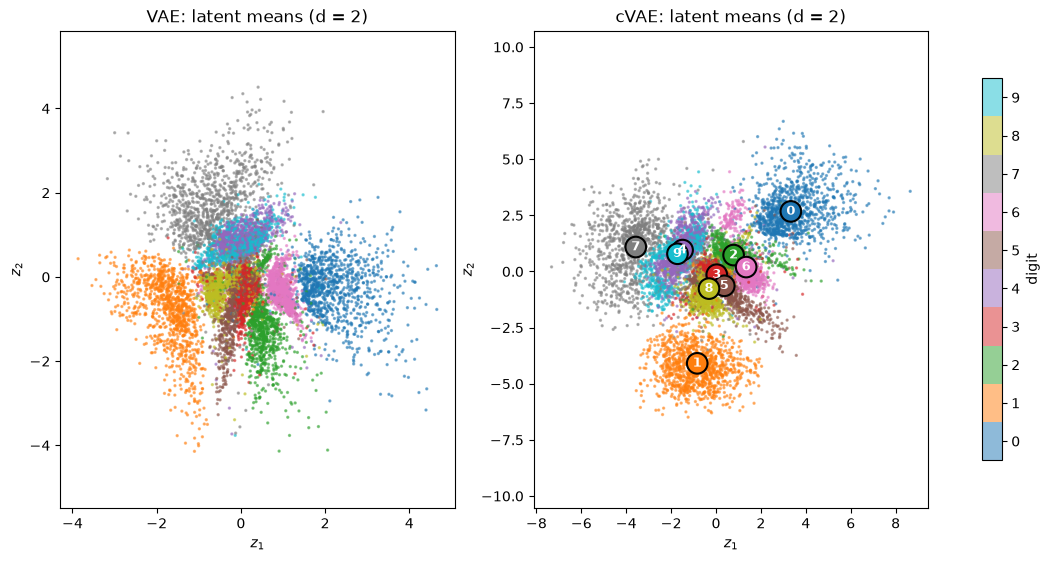

In [11]:
codes = {label: latent_codes(model, val_loader) for label, model in models.items()}

fig, axes = plt.subplots(1, 2, figsize=(14, 6.2))
for ax, (label, (z, y)) in zip(axes, codes.items()):
    if d == 2:
        proj, project, title = z, (lambda a: a), f"{label}: latent means (d = 2)"
    else:
        proj, project, explained = pca(z)
        title = f"{label}: PCA of latent means (d = {d}, {explained.sum():.0%} variance shown)"

    sc = ax.scatter(proj[:, 0], proj[:, 1], c=y, cmap="tab10", vmin=-0.5, vmax=9.5, s=2, alpha=0.5)
    if label == "cVAE":
        mp = project(class_means(models["cVAE"]))
        ax.scatter(mp[:, 0], mp[:, 1], c=np.arange(10), cmap="tab10", vmin=-0.5, vmax=9.5,
                   s=220, marker="o", edgecolors="black", linewidths=1.5)
        for c, (px, py) in enumerate(mp):
            ax.text(px, py, str(c), ha="center", va="center", fontsize=9, fontweight="bold", color="white")
    ax.set(title=title, xlabel="component 1" if d > 2 else "$z_1$", ylabel="component 2" if d > 2 else "$z_2$")
    ax.set_aspect("equal", adjustable="datalim")

fig.colorbar(sc, ax=axes, ticks=range(10), label="digit", shrink=0.8)
pdf.savefig(fig, bbox_inches="tight")
plt.show()

fig.savefig(FIG_DIR / "latent_structure.pdf", bbox_inches="tight")


## 3. How strongly do the codes cluster by class?

- **Separation ratio**: total between-class variance divided by total within-class variance of the latent means
  (in the full d-dimensional space). Larger means tighter, better separated class clusters.
- **Nearest-class-centroid accuracy**: classify each validation image by the closest class centroid of the codes
  (the empirical centroid for both models; for the cVAE also the learned prior mean m(y)).
  This uses no trained classifier, so it directly reflects the geometry of the latent space.

In [8]:
def separation_ratio(z, y):
    overall = z.mean(axis=0)
    between = sum((y == c).sum() * ((z[y == c].mean(axis=0) - overall) ** 2).sum() for c in range(10))
    within = sum(((z[y == c] - z[y == c].mean(axis=0)) ** 2).sum() for c in range(10))
    return between / within


def nearest_centroid_accuracy(z, y, centroids):
    dist = ((z[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2)    # (n, 10)
    return (dist.argmin(axis=1) == y).mean()


print(f"{'model':6s} {'separation':>11s} {'NCC (empirical)':>17s} {'NCC (prior means)':>19s}")
for label, (z, y) in codes.items():
    empirical = np.stack([z[y == c].mean(axis=0) for c in range(10)])
    ncc_emp = nearest_centroid_accuracy(z, y, empirical)
    ncc_prior = (f"{nearest_centroid_accuracy(z, y, class_means(models[label])):.3f}"
                 if hasattr(models[label], "classmeans") else "-")
    print(f"{label:6s} {separation_ratio(z, y):11.3f} {ncc_emp:17.3f} {ncc_prior:>19s}")

m_np = class_means(models["cVAE"])
pairwise = np.sqrt(((m_np[:, None] - m_np[None]) ** 2).sum(axis=2))
print(f"\ncVAE class means: norms {np.linalg.norm(m_np, axis=1).round(2)}")
print(f"smallest distance between two class means: {pairwise[np.triu_indices(10, 1)].min():.2f} "
      f"(prior SD is 1 per dimension)")

model   separation   NCC (empirical)   NCC (prior means)
VAE          2.538             0.701                   -
cVAE         3.682             0.706               0.708

cVAE class means: norms [4.27 4.17 1.07 0.15 1.77 0.73 1.36 3.74 0.82 1.89]
smallest distance between two class means: 0.28 (prior SD is 1 per dimension)


## Save

In [9]:
pdf.close()
print("saved", FIG_DIR / "d5_cvae.pdf")

saved /Users/Jeremie/Postdoc/representation_learning/vae_mnist/figures/d5_cvae.pdf
